# Catching material search declines with ten reviews per client

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shenone77/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

FlyRank ML Internship · Refresh / Content Opportunity Scoring · Shenone77

## 1. Question

Which pages should a content editor review first when they have ten slots per client? The queue ranks pages with measurable prior search visibility by risk of a material 30-day impression loss. It gives the editor a reason code and a manual check. A false alarm uses part of the budget, and a missed drop postpones investigation of a page that lost visibility.

## 2. Data and split

Use the FlyRank v20260703 warehouse. Aggregate the daily performance fact at one page per client per cutoff and join the client and content dimensions for tracking start and creation age. Training uses March 2–31 features and April 1–30 outcomes. The June holdout uses May 2–31 features and June 1–30 outcomes.

Eligibility at the cutoff requires 30 valid observed GSC days, tracking that started on or before the feature window, a known creation date, and at least 300 prior impressions. Keep a missing follow-up outcome unresolved. The retrospective metrics use only pages with 30 valid follow-up days. The operational queue uses the full pre-cutoff population.

In [1]:
from pathlib import Path
import subprocess
import sys

token = None
if "google.colab" in sys.modules:
    from google.colab import userdata
    root = Path("/content/flyrank-ml-internship")
    if not root.is_dir():
        subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/Shenone77/flyrank-ml-internship.git", str(root)],
            check=True,
        )
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")], check=True)
    token = userdata.get("HF_TOKEN")
else:
    here = Path.cwd().resolve()
    root = next(
        (p for p in (here, *here.parents) if (p / "work/notebooks/capstone_analysis.py").is_file()),
        None,
    )
    if root is None:
        raise FileNotFoundError("Open this notebook inside the submission repository.")

sys.path.insert(0, str(root / "work/notebooks"))
from capstone_analysis import run
import pandas as pd

metrics = run(root, token)
coverage = pd.DataFrame({"Training": metrics["train"], "June holdout": metrics["holdout"]}).T
display(coverage.round(3))

Loading train page windows at 2026-04-01...


train: 54,459 eligible pages.


Loading test page windows at 2026-06-01...


test: 65,176 eligible pages.


,eligible_pages,observed_outcomes,unresolved_outcomes,clients_with_observed_outcomes,material_drops,base_rate
Training,54459.0,47770.0,6689.0,30.0,17761.0,0.372
June holdout,65176.0,54692.0,10484.0,37.0,28198.0,0.516


## 3. Methodology and leakage checks

A material drop means at least 150 fewer impressions and at least 30% fewer impressions in the following 30 days. The exposure rule ranks by prior impressions and adds 25% for prior CTR at or below 0.5%, as in ML-07. A standardized logistic score adds jointly fitted weights for log prior impressions, prior CTR, age at the cutoff, prior days with impressions, and the share of prior impressions in the last 15 days.

Fit scaling and model weights on the April-outcome frame. Apply the same frozen rule and trained model to the June-outcome frame. Every model input is available before the cutoff. The SQL validates page-day grain and uses keys for joins and grouping. It excludes later activity, GA4, refreshed metadata, status flags, titles, and queries from predictors. An earlier client-holdout exercise informed the research question. The June split now tests transfer over time and may include the same clients or pages.

## 4. Results and interpretation

Primary metric: mean Precision@10 across clients with at least ten observable eligible pages. Every eligible client contributes equal weight. Compare both methods with the same random-queue expectation. The pooled top 50 is a secondary metric that shows how a single global queue behaves. The interval resamples clients and compares their paired differences within this single holdout.

In the saved run, the model found 218 material drops in 320 client-balanced review slots and the rule found 103. The pooled top 50 tells a different story about exposure. The rule's 22 correct picks accounted for approximately 2.03 million lost impressions, while the model's 48 accounted for about 0.63 million. More correct picks can coexist with less visibility loss covered. The strongest fitted association was a lower late-window share. Prior active days had a zero fitted coefficient on this frame.

In [2]:
comparison = pd.DataFrame.from_dict(metrics["methods"], orient="index")
display(comparison.round(4))
eval_info = metrics["evaluation"]
lo, hi = eval_info["macro_delta_client_bootstrap_95"]
print(f"Clients in the 10-slot comparison: {eval_info['clients_at_k10']}")
print(f"Expected random client-average Precision@10: {eval_info['macro_random_precision_at_10']:.1%}")
print(f"Logistic minus rule: {100 * eval_info['macro_delta']:+.1f} points (95% client-bootstrap interval {100 * lo:+.1f} to {100 * hi:+.1f}).")
print(f"Clients better / tied / worse: {eval_info['better_clients']} / {eval_info['tied_clients']} / {eval_info['worse_clients']}.")

error_table = comparison[["drops_at_50", "clients_at_50"]].assign(
    top_50_false_alarms=lambda table: 50 - table["drops_at_50"],
    observed_drops_outside_top_50=lambda table: metrics["holdout"]["material_drops"] - table["drops_at_50"],
)
display(error_table)
display(pd.Series(metrics["standardized_coefficients"], name="Standardized coefficient").round(3))

,precision_at_50,drops_at_50,clients_at_50,lost_impressions_among_hits_at_50,average_precision,macro_precision_at_10
Exposure rule,0.44,22,10,2034384,0.5411,0.3219
Logistic ranking,0.96,48,15,634396,0.6854,0.6812


Clients in the 10-slot comparison: 32
Expected random client-average Precision@10: 34.7%
Logistic minus rule: +35.9 points (95% client-bootstrap interval +28.4 to +43.8).
Clients better / tied / worse: 29 / 3 / 0.


,drops_at_50,clients_at_50,top_50_false_alarms,observed_drops_outside_top_50
Exposure rule,22,10,28,28176
Logistic ranking,48,15,2,28150


log_prior_impressions    0.079
prior_ctr_pct           -0.398
age_at_cutoff_days      -0.013
prior_active_days        0.000
prior_late_share        -0.637
Name: Standardized coefficient, dtype: float64

## 5. Limitations

This release is an unbalanced panel. Pages with unresolved follow-up cannot be labeled reliably. The operational exporter retains them because that future information is unavailable when an editor makes a decision. The prior impression count helps set both the filter and the decline label's reference level, so coefficients are directional and may partly reflect the outcome definition. Precision measures agreement with the observed loss rule. A search drop can come from demand, ranking, indexing, or content changes, and comparing scores does not establish what a refresh would recover.

## 6. Ranked recommendations

Cap each client at ten human reviews. Prefer the learned score for a pilot only if the paired interval clears zero. Use the transparent exposure rule otherwise. Examine fading visibility against indexing or demand, inspect query and snippet fit when prior CTR is low, and review page and query trends when exposure alone drives prioritization. Monitor rows outside the budget. Confirm seasonality, tracking health, and planned migrations before edits. Record time spent and useful findings, and re-evaluate if Precision@10 falls below the rule in two recent labeled windows.

In [3]:
print(f"Pilot queue score: {metrics['recommended_queue_score']}")
display(pd.Series(metrics["review_queue_reasons"], name="Review slots across clients"))
print("The local queue includes reason codes and excludes outcomes. Rerun to regenerate it.")

Pilot queue score: model_score


PRIOR_EXPOSURE_FADING    275
LOW_PRIOR_CTR             72
EXPOSURE_AT_STAKE         21
Name: Review slots across clients, dtype: int64

The local queue includes reason codes and excludes outcomes. Rerun to regenerate it.


## 7. Figure and reproducibility

Use this aggregate figure and the metrics receipt to trace the paper's numbers. Run all cells or install the repository requirements and run the companion Python script. The warehouse revision and seed are recorded. Store an approved Hugging Face Read token in the machine's Hugging Face login or in Colab Secrets as HF_TOKEN.

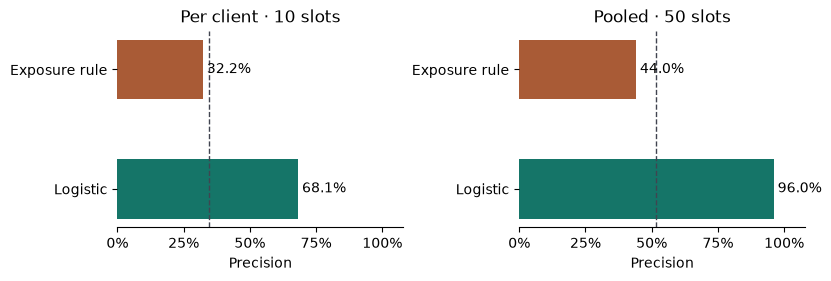

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

colors = ["#a95b36", "#157568"]
fig, axes = plt.subplots(1, 2, figsize=(8.2, 2.7), layout="constrained")
columns = ["macro_precision_at_10", "precision_at_50"]
titles = ["Per client · 10 slots", "Pooled · 50 slots"]
refs = [metrics["evaluation"]["macro_random_precision_at_10"], metrics["holdout"]["base_rate"]]
for ax, column, title, ref in zip(axes, columns, titles, refs):
    bars = ax.barh(["Exposure rule", "Logistic"], comparison[column], color=colors, height=0.5)
    ax.set(title=title, xlim=(0, 1.08), xlabel="Precision")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.axvline(ref, linestyle="--", linewidth=1, color="#414450")
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in comparison[column]], padding=3)
    ax.invert_yaxis()
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

The dashed line in each panel shows the expected precision of a random queue under that panel's allocation. The two panels answer different budget questions.

[Companion code](capstone_analysis.py) · [Aggregate metrics](../outputs/capstone_metrics.json) · [Repository](https://github.com/Shenone77/flyrank-ml-internship)

## Acknowledgments & data credit

[Built on the FlyRank ML Internship dataset](https://flyrank.ai).